# Homework 4 (Lecture 6): Numerical Greeks
Carlos Chipantiza (Neptun EACN90), Financial Processes BMETE95MM14, course id 54932fw.

**Assignment (notebook_flatvol.ipynb, cell 26).** *Introduce two class variables in Pricer that store the finite difference method (forward, backward, central) to be used in numerical greek calculation, and whether the bump size is absolute or relative. Create two Enums to store the labels. Implement all combinations for delta and gamma calculation. Compare greeks using the analytic and the finite difference approximation on a set of European options and visualize the numerical error. Compare absolute and relative bumping and suggest optimal bump sizes.* **(15 points)**

Report: `4_Homework_Lesson06.pdf`. The cells below are exact copies of the files of this folder.

In [1]:
# Setup: in Colab mount Drive and go to the homework folder (copy QuantCourseBP/mkt into it);
# locally (repository) use the folder of this notebook.
import os
import sys
from pathlib import Path
try:
    from google.colab import drive
    drive.mount('/content/drive')
    here = Path('/content/drive/MyDrive/POSGRADOS/HUNGRIA/MASTER/1/FNANCIAL PROCESS /HOMEWORKS/4_HW_LECTURE_6')
except ImportError:
    here = Path.cwd()
os.chdir(here)
sys.path.insert(0, str(here))
repo_root = next(p for p in [here, *here.parents] if (p / 'mkt' / 'spot.csv').exists())
from market_data import MarketData
MarketData.market_folder = repo_root / 'mkt'                    # csv files of Lecture 6
MarketData.initialize()
print('market data from', MarketData.market_folder.relative_to(repo_root.parent))

market data from QuantCourseBP/mkt


## 1. Professor's code
`solution/pricer.py` of Lecture 6: `calc_delta` and `calc_gamma` by bump and revaluation, central difference, relative bump 1% (cells 23-25).

In [2]:
from __future__ import annotations
from abc import ABC, abstractmethod
import copy
import numpy as np
from scipy.stats import norm
from enums import *
from contract import *
from model import *


# TASK:
# Implement calc_delta() functions using finite difference approximation


class Params:
    pass


class Pricer(ABC):
    # Only for theta calculation via bump and revaluation
    valuation_time: float = 0.0
    relative_bump_size: float = 0.01

    def __init__(self, contract: Contract, model: MarketModel, params: Params) -> None:
        self.contract: Contract = contract
        self.model: MarketModel = model
        self.params: Params = params

    @classmethod
    def create_pricer(cls, contract: Contract, model: MarketModel, params: Params) -> Pricer:
        instance = cls(contract, model, params)
        return instance

    @abstractmethod
    def calc_fair_value(self) -> float:
        pass

    def calc_delta(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        bump_size = self.relative_bump_size * self.model.spot
        bumped_fair_values = list()
        for b in (bump_size, -bump_size):
            model_to_bump = copy.deepcopy(self.model)
            model_to_bump.bump_spot(b)
            bumped_pricer = self.create_pricer(self.contract, model_to_bump, self.params)
            bumped_fair_values.append(bumped_pricer.calc_fair_value())
            del bumped_pricer
            del model_to_bump
        return (bumped_fair_values[0] - bumped_fair_values[1]) / (2 * bump_size)

    def calc_gamma(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        bump_size = self.relative_bump_size * self.model.spot
        bumped_fair_values = list()
        for b in (bump_size, -bump_size):
            model_to_bump = copy.deepcopy(self.model)
            model_to_bump.bump_spot(b)
            bumped_pricer = self.create_pricer(self.contract, model_to_bump, self.params)
            bumped_fair_values.append(bumped_pricer.calc_fair_value())
            del bumped_pricer
            del model_to_bump
        return (bumped_fair_values[0] - 2 * self.calc_fair_value() + bumped_fair_values[1]) / (bump_size ** 2)

    def calc_vega(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        strike = self.contract.strike
        expiry = self.contract.expiry
        vol = self.model.get_vol(strike, expiry)
        bump_size = self.relative_bump_size * vol
        bumped_fair_values = list()
        for b in (bump_size, -bump_size):
            model = copy.deepcopy(self.model)
            model.bump_volgrid(b)
            bumped_pricer = self.create_pricer(self.contract, model, self.params)
            bumped_fair_values.append(bumped_pricer.calc_fair_value())
            del bumped_pricer
            del model
        return (bumped_fair_values[0] - bumped_fair_values[1]) / (2 * bump_size)

    def calc_theta(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        bump_size = 1.0 / 365.0
        bumped_pricer = copy.deepcopy(self)
        bumped_pricer.valuation_time += bump_size
        bumped_fair_value = bumped_pricer.calc_fair_value()
        del bumped_pricer
        return (bumped_fair_value - self.calc_fair_value()) / bump_size

    def calc_rho(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        bump_size = self.relative_bump_size * self.model.risk_free_rate
        bumped_fair_values = list()
        for b in (bump_size, -bump_size):
            model = copy.deepcopy(self.model)
            model.bump_rate(b)
            bumped_pricer = self.create_pricer(self.contract, model, self.params)
            bumped_fair_values.append(bumped_pricer.calc_fair_value())
            del bumped_pricer
            del model
        return (bumped_fair_values[0] - bumped_fair_values[1]) / (2 * bump_size)

    def raise_unsupported_greek_method_error(
            self,
            method: str,
            supported: tuple[GreekMethod, ...] = (_.value for _ in GreekMethod)) -> None:
        raise ValueError(f'Unsupported GreekMethod {method} for Pricer {type(self).__name__}. '
                         f'Supported methods are: {", ".join(supported)}')

    def raise_pricer_not_implemented_error(self) -> None:
        raise RuntimeError(f'The pricing of this type of contract has not been implemented yet.')


class ForwardAnalyticPricer(Pricer):
    supported_deriv_type: tuple[PutCallFwd, ...] = (PutCallFwd.FWD,)

    def __init__(self, contract: ForwardContract, model: MarketModel, params: Params) -> None:
        if not isinstance(contract, ForwardContract):
            raise TypeError(f'Contract must be of type ForwardContract but received {type(contract).__name__}')
        super().__init__(contract, model, params)

    def calc_fair_value(self) -> float:
        direction = self.contract.direction
        spot = self.model.spot
        strike = self.contract.strike
        time_to_expiry = self.contract.expiry - self.valuation_time
        df = self.model.calc_df(time_to_expiry)
        if self.contract.derivative_type == PutCallFwd.FWD:
            return direction * (spot - strike * df)
        else:
            self.contract.raise_incorrect_derivative_type_error(self.supported_deriv_type)

    def calc_delta(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            return self.contract.direction * 1.0
        elif method == GreekMethod.BUMP:
            return super().calc_delta(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_gamma(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            return 0.0
        elif method == GreekMethod.BUMP:
            return super().calc_gamma(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_vega(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            return 0.0
        elif method == GreekMethod.BUMP:
            return super().calc_vega(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_theta(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            strike = self.contract.strike
            time_to_expiry = self.contract.expiry - self.valuation_time
            rate = self.model.risk_free_rate
            df = self.model.calc_df(time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.FWD:
                greek = -1.0 * strike * df * rate
            else:
                self.contract.raise_incorrect_derivative_type_error(self.supported_deriv_type)
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_theta(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_rho(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            strike = self.contract.strike
            time_to_expiry = self.contract.expiry - self.valuation_time
            df = self.model.calc_df(time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.FWD:
                greek = strike * df * time_to_expiry
            else:
                self.contract.raise_incorrect_derivative_type_error(self.supported_deriv_type)
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_rho(method)
        else:
            self.raise_unsupported_greek_method_error(method)


class EuropeanAnalyticPricer(Pricer):
    @staticmethod
    def calc_d1(spot_over_strike: float, vol: float, rate: float, time_to_expiry: float) -> float:
        return 1 / (vol * np.sqrt(time_to_expiry)) * (np.log(spot_over_strike) + (rate + vol**2 / 2) * time_to_expiry)

    @staticmethod
    def calc_d2(spot_over_strike: float, vol: float, rate: float, time_to_expiry: float) -> float:
        d1 = EuropeanAnalyticPricer.calc_d1(spot_over_strike, vol, rate, time_to_expiry)
        return d1 - vol * np.sqrt(time_to_expiry)

    def __init__(self, contract: EuropeanContract, model: MarketModel, params: Params) -> None:
        if not isinstance(contract, EuropeanContract):
            raise TypeError(f'Contract must be of type EuropeanContract but received {type(contract).__name__}')
        super().__init__(contract, model, params)

    def calc_fair_value(self) -> float:
        direction = self.contract.direction
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        spot = self.model.spot
        vol = self.model.get_vol(strike, expiry)
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        if self.contract.derivative_type == PutCallFwd.CALL:
            return direction * (spot * norm.cdf(d1) - strike * df * norm.cdf(d2))
        elif self.contract.derivative_type == PutCallFwd.PUT:
            return direction * (strike * df * norm.cdf(-d2) - spot * norm.cdf(-d1))
        else:
            self.contract.raise_incorrect_derivative_type_error()

    def calc_delta(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            spot = self.model.spot
            strike = self.contract.strike
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.CALL:
                greek = norm.cdf(d1)
            elif self.contract.derivative_type == PutCallFwd.PUT:
                greek = -norm.cdf(-d1)
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_delta(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_gamma(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            spot = self.model.spot
            strike = self.contract.strike
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
                greek = norm.pdf(d1) / (spot * vol * np.sqrt(time_to_expiry))
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_gamma(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_vega(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            spot = self.model.spot
            strike = self.contract.strike
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            df = self.model.calc_df(time_to_expiry)
            d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
                greek = strike * df * norm.pdf(d2) * np.sqrt(time_to_expiry)
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_vega(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_theta(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            strike = self.contract.strike
            spot = self.model.spot
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            df = self.model.calc_df(time_to_expiry)
            d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
            d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.CALL:
                greek = -1.0 * ((spot * norm.pdf(d1) * vol) / (2 * np.sqrt(time_to_expiry))
                                + rate * strike * df * norm.cdf(d2))
            elif self.contract.derivative_type == PutCallFwd.PUT:
                greek = -1.0 * ((spot * norm.pdf(d1) * vol) / (2 * np.sqrt(time_to_expiry))
                                - rate * strike * df * norm.cdf(-d2))
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_theta(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_rho(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            strike = self.contract.strike
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            spot = self.model.spot
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            df = self.model.calc_df(time_to_expiry)
            d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.CALL:
                greek = strike * time_to_expiry * df * norm.cdf(d2)
            elif self.contract.derivative_type == PutCallFwd.PUT:
                greek = -strike * time_to_expiry * df * norm.cdf(-d2)
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_rho(method)
        else:
            self.raise_unsupported_greek_method_error(method)

**Test of the professor's code** (running example: ATM 1Y call on BLUECHIP_BANK, FlatVol model).

In [3]:
und = Stock.BLUECHIP_BANK
spot = MarketData.get_spot()[und]
call = EuropeanContract(und, PutCallFwd.CALL, LongShort.LONG, spot, 1.0)
pricer = EuropeanAnalyticPricer(call, FlatVolModel(und), Params())
for greek in ('delta', 'gamma'):
    analytic = getattr(pricer, f'calc_{greek}')(GreekMethod.ANALYTIC)
    bump = getattr(pricer, f'calc_{greek}')(GreekMethod.BUMP)
    print(f'{greek}: analytic = {analytic:.6f}, bump = {bump:.6f}, error = {bump - analytic:.2e}')

delta: analytic = 0.626163, bump = 0.626132, error = -3.06e-05
gamma: analytic = 0.007642, bump = 0.007642, error = -1.05e-07


## 2. NEW CODE: the two Enums (end of `enums.py`)

In [4]:
from enum import Enum


# =====================================================================================================
# Homework 4 (NEW CODE): labels of the numerical greeks (finite differences, Lecture 6, cells 23-24).
# =====================================================================================================
class FDMethod(str, Enum):
    FORWARD: str = 'FORWARD'
    BACKWARD: str = 'BACKWARD'
    CENTRAL: str = 'CENTRAL'


class BumpType(str, Enum):
    ABSOLUTE: str = 'ABSOLUTE'
    RELATIVE: str = 'RELATIVE'

**Test**

In [5]:
print([m.value for m in FDMethod], [b.value for b in BumpType])

['FORWARD', 'BACKWARD', 'CENTRAL'] ['ABSOLUTE', 'RELATIVE']


## 3. NEW VERSION of `Pricer` (`pricer.py`)
Changes # 1 - # 4 inside `class Pricer`: class variables `fd_method`, `bump_type` (and `absolute_bump_size`), the bump size and the bumped price, and all combinations in `calc_delta`, `calc_gamma`. The rest of the file is the professor's code, unchanged.

In [6]:
from __future__ import annotations
from abc import ABC, abstractmethod
import copy
import numpy as np
from scipy.stats import norm
from enums import *
from contract import *
from model import *


# TASK:
# Implement calc_delta() functions using finite difference approximation
# Homework 4: NEW VERSION of Pricer (changes # 1 - # 4): finite difference method and bump type as class variables,
# all combinations in calc_delta and calc_gamma. The rest of the file is the lecture's solution, unchanged.


class Params:
    pass


class Pricer(ABC):
    # Only for theta calculation via bump and revaluation
    valuation_time: float = 0.0
    relative_bump_size: float = 0.01
    # change # 1 (added: two new class variables and the size of an absolute bump)
    fd_method: FDMethod = FDMethod.CENTRAL          # FORWARD, BACKWARD or CENTRAL difference
    bump_type: BumpType = BumpType.RELATIVE         # h = relative_bump_size * S, or h = absolute_bump_size
    absolute_bump_size: float = 1.0                 # in units of the spot price
    # end change # 1

    def __init__(self, contract: Contract, model: MarketModel, params: Params) -> None:
        self.contract: Contract = contract
        self.model: MarketModel = model
        self.params: Params = params

    @classmethod
    def create_pricer(cls, contract: Contract, model: MarketModel, params: Params) -> Pricer:
        instance = cls(contract, model, params)
        return instance

    @abstractmethod
    def calc_fair_value(self) -> float:
        pass

    # change # 2 (added: the bump size h, and the fair value at the bumped spot S + bump)
    def calc_spot_bump_size(self) -> float:
        if self.bump_type == BumpType.RELATIVE:
            return self.relative_bump_size * self.model.spot
        elif self.bump_type == BumpType.ABSOLUTE:
            return self.absolute_bump_size
        else:
            raise ValueError(f'Unsupported BumpType {self.bump_type}')

    def calc_fair_value_bumped_spot(self, bump: float) -> float:
        model_to_bump = copy.deepcopy(self.model)
        model_to_bump.bump_spot(bump)
        bumped_pricer = self.create_pricer(self.contract, model_to_bump, self.params)
        return bumped_pricer.calc_fair_value()
    # end change # 2

    def calc_delta(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        # change # 3
        #Delete.bump_size = self.relative_bump_size * self.model.spot
        #Delete.bumped_fair_values = list()
        #Delete.for b in (bump_size, -bump_size):
        #Delete.    model_to_bump = copy.deepcopy(self.model)
        #Delete.    model_to_bump.bump_spot(b)
        #Delete.    bumped_pricer = self.create_pricer(self.contract, model_to_bump, self.params)
        #Delete.    bumped_fair_values.append(bumped_pricer.calc_fair_value())
        #Delete.    del bumped_pricer
        #Delete.    del model_to_bump
        #Delete.return (bumped_fair_values[0] - bumped_fair_values[1]) / (2 * bump_size)
        # replace by
        h = self.calc_spot_bump_size()
        if self.fd_method == FDMethod.FORWARD:
            return (self.calc_fair_value_bumped_spot(h) - self.calc_fair_value()) / h
        elif self.fd_method == FDMethod.BACKWARD:
            return (self.calc_fair_value() - self.calc_fair_value_bumped_spot(-h)) / h
        elif self.fd_method == FDMethod.CENTRAL:
            return (self.calc_fair_value_bumped_spot(h) - self.calc_fair_value_bumped_spot(-h)) / (2 * h)
        else:
            raise ValueError(f'Unsupported FDMethod {self.fd_method}')
        # end change # 3

    def calc_gamma(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        # change # 4
        #Delete.bump_size = self.relative_bump_size * self.model.spot
        #Delete.bumped_fair_values = list()
        #Delete.for b in (bump_size, -bump_size):
        #Delete.    model_to_bump = copy.deepcopy(self.model)
        #Delete.    model_to_bump.bump_spot(b)
        #Delete.    bumped_pricer = self.create_pricer(self.contract, model_to_bump, self.params)
        #Delete.    bumped_fair_values.append(bumped_pricer.calc_fair_value())
        #Delete.    del bumped_pricer
        #Delete.    del model_to_bump
        #Delete.return (bumped_fair_values[0] - 2 * self.calc_fair_value() + bumped_fair_values[1]) / (bump_size ** 2)
        # replace by
        h = self.calc_spot_bump_size()
        if self.fd_method == FDMethod.FORWARD:
            return (self.calc_fair_value_bumped_spot(2 * h) - 2 * self.calc_fair_value_bumped_spot(h)
                    + self.calc_fair_value()) / h ** 2
        elif self.fd_method == FDMethod.BACKWARD:
            return (self.calc_fair_value() - 2 * self.calc_fair_value_bumped_spot(-h)
                    + self.calc_fair_value_bumped_spot(-2 * h)) / h ** 2
        elif self.fd_method == FDMethod.CENTRAL:
            return (self.calc_fair_value_bumped_spot(h) - 2 * self.calc_fair_value()
                    + self.calc_fair_value_bumped_spot(-h)) / h ** 2
        else:
            raise ValueError(f'Unsupported FDMethod {self.fd_method}')
        # end change # 4

    def calc_vega(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        strike = self.contract.strike
        expiry = self.contract.expiry
        vol = self.model.get_vol(strike, expiry)
        bump_size = self.relative_bump_size * vol
        bumped_fair_values = list()
        for b in (bump_size, -bump_size):
            model = copy.deepcopy(self.model)
            model.bump_volgrid(b)
            bumped_pricer = self.create_pricer(self.contract, model, self.params)
            bumped_fair_values.append(bumped_pricer.calc_fair_value())
            del bumped_pricer
            del model
        return (bumped_fair_values[0] - bumped_fair_values[1]) / (2 * bump_size)

    def calc_theta(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        bump_size = 1.0 / 365.0
        bumped_pricer = copy.deepcopy(self)
        bumped_pricer.valuation_time += bump_size
        bumped_fair_value = bumped_pricer.calc_fair_value()
        del bumped_pricer
        return (bumped_fair_value - self.calc_fair_value()) / bump_size

    def calc_rho(self, method: GreekMethod) -> float:
        if method != GreekMethod.BUMP:
            self.raise_unsupported_greek_method_error(method, (GreekMethod.BUMP,))
        bump_size = self.relative_bump_size * self.model.risk_free_rate
        bumped_fair_values = list()
        for b in (bump_size, -bump_size):
            model = copy.deepcopy(self.model)
            model.bump_rate(b)
            bumped_pricer = self.create_pricer(self.contract, model, self.params)
            bumped_fair_values.append(bumped_pricer.calc_fair_value())
            del bumped_pricer
            del model
        return (bumped_fair_values[0] - bumped_fair_values[1]) / (2 * bump_size)

    def raise_unsupported_greek_method_error(
            self,
            method: str,
            supported: tuple[GreekMethod, ...] = (_.value for _ in GreekMethod)) -> None:
        raise ValueError(f'Unsupported GreekMethod {method} for Pricer {type(self).__name__}. '
                         f'Supported methods are: {", ".join(supported)}')

    def raise_pricer_not_implemented_error(self) -> None:
        raise RuntimeError(f'The pricing of this type of contract has not been implemented yet.')


class ForwardAnalyticPricer(Pricer):
    supported_deriv_type: tuple[PutCallFwd, ...] = (PutCallFwd.FWD,)

    def __init__(self, contract: ForwardContract, model: MarketModel, params: Params) -> None:
        if not isinstance(contract, ForwardContract):
            raise TypeError(f'Contract must be of type ForwardContract but received {type(contract).__name__}')
        super().__init__(contract, model, params)

    def calc_fair_value(self) -> float:
        direction = self.contract.direction
        spot = self.model.spot
        strike = self.contract.strike
        time_to_expiry = self.contract.expiry - self.valuation_time
        df = self.model.calc_df(time_to_expiry)
        if self.contract.derivative_type == PutCallFwd.FWD:
            return direction * (spot - strike * df)
        else:
            self.contract.raise_incorrect_derivative_type_error(self.supported_deriv_type)

    def calc_delta(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            return self.contract.direction * 1.0
        elif method == GreekMethod.BUMP:
            return super().calc_delta(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_gamma(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            return 0.0
        elif method == GreekMethod.BUMP:
            return super().calc_gamma(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_vega(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            return 0.0
        elif method == GreekMethod.BUMP:
            return super().calc_vega(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_theta(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            strike = self.contract.strike
            time_to_expiry = self.contract.expiry - self.valuation_time
            rate = self.model.risk_free_rate
            df = self.model.calc_df(time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.FWD:
                greek = -1.0 * strike * df * rate
            else:
                self.contract.raise_incorrect_derivative_type_error(self.supported_deriv_type)
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_theta(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_rho(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            strike = self.contract.strike
            time_to_expiry = self.contract.expiry - self.valuation_time
            df = self.model.calc_df(time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.FWD:
                greek = strike * df * time_to_expiry
            else:
                self.contract.raise_incorrect_derivative_type_error(self.supported_deriv_type)
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_rho(method)
        else:
            self.raise_unsupported_greek_method_error(method)


class EuropeanAnalyticPricer(Pricer):
    @staticmethod
    def calc_d1(spot_over_strike: float, vol: float, rate: float, time_to_expiry: float) -> float:
        return 1 / (vol * np.sqrt(time_to_expiry)) * (np.log(spot_over_strike) + (rate + vol**2 / 2) * time_to_expiry)

    @staticmethod
    def calc_d2(spot_over_strike: float, vol: float, rate: float, time_to_expiry: float) -> float:
        d1 = EuropeanAnalyticPricer.calc_d1(spot_over_strike, vol, rate, time_to_expiry)
        return d1 - vol * np.sqrt(time_to_expiry)

    def __init__(self, contract: EuropeanContract, model: MarketModel, params: Params) -> None:
        if not isinstance(contract, EuropeanContract):
            raise TypeError(f'Contract must be of type EuropeanContract but received {type(contract).__name__}')
        super().__init__(contract, model, params)

    def calc_fair_value(self) -> float:
        direction = self.contract.direction
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        spot = self.model.spot
        vol = self.model.get_vol(strike, expiry)
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        if self.contract.derivative_type == PutCallFwd.CALL:
            return direction * (spot * norm.cdf(d1) - strike * df * norm.cdf(d2))
        elif self.contract.derivative_type == PutCallFwd.PUT:
            return direction * (strike * df * norm.cdf(-d2) - spot * norm.cdf(-d1))
        else:
            self.contract.raise_incorrect_derivative_type_error()

    def calc_delta(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            spot = self.model.spot
            strike = self.contract.strike
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.CALL:
                greek = norm.cdf(d1)
            elif self.contract.derivative_type == PutCallFwd.PUT:
                greek = -norm.cdf(-d1)
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_delta(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_gamma(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            spot = self.model.spot
            strike = self.contract.strike
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
                greek = norm.pdf(d1) / (spot * vol * np.sqrt(time_to_expiry))
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_gamma(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_vega(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            spot = self.model.spot
            strike = self.contract.strike
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            df = self.model.calc_df(time_to_expiry)
            d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
                greek = strike * df * norm.pdf(d2) * np.sqrt(time_to_expiry)
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_vega(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_theta(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            strike = self.contract.strike
            spot = self.model.spot
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            df = self.model.calc_df(time_to_expiry)
            d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
            d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.CALL:
                greek = -1.0 * ((spot * norm.pdf(d1) * vol) / (2 * np.sqrt(time_to_expiry))
                                + rate * strike * df * norm.cdf(d2))
            elif self.contract.derivative_type == PutCallFwd.PUT:
                greek = -1.0 * ((spot * norm.pdf(d1) * vol) / (2 * np.sqrt(time_to_expiry))
                                - rate * strike * df * norm.cdf(-d2))
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_theta(method)
        else:
            self.raise_unsupported_greek_method_error(method)

    def calc_rho(self, method: GreekMethod) -> float:
        if method == GreekMethod.ANALYTIC:
            greek = 0.0
            strike = self.contract.strike
            expiry = self.contract.expiry
            time_to_expiry = expiry - self.valuation_time
            spot = self.model.spot
            vol = self.model.get_vol(strike, expiry)
            rate = self.model.risk_free_rate
            df = self.model.calc_df(time_to_expiry)
            d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
            if self.contract.derivative_type == PutCallFwd.CALL:
                greek = strike * time_to_expiry * df * norm.cdf(d2)
            elif self.contract.derivative_type == PutCallFwd.PUT:
                greek = -strike * time_to_expiry * df * norm.cdf(-d2)
            else:
                self.contract.raise_incorrect_derivative_type_error()
            return self.contract.direction * greek
        elif method == GreekMethod.BUMP:
            return super().calc_rho(method)
        else:
            self.raise_unsupported_greek_method_error(method)

**Test of the NEW VERSION** (`q1_fd_greeks_demo.py`): defaults = lecture, the six combinations, checks.

In [7]:
# running example: ATM 1Y call on BLUECHIP_BANK, FlatVol model (Lecture 6, cell 22)
und = Stock.BLUECHIP_BANK
spot = MarketData.get_spot()[und]
call = EuropeanContract(und, PutCallFwd.CALL, LongShort.LONG, spot, 1.0)
pricer = EuropeanAnalyticPricer(call, FlatVolModel(und), Params())
delta, gamma = pricer.calc_delta(GreekMethod.ANALYTIC), pricer.calc_gamma(GreekMethod.ANALYTIC)
print(f'ATM call: S = K = {spot}, T = 1, vol = {pricer.model.get_vol(spot, 1.0):.6f}, '
      f'value = {pricer.calc_fair_value():.6f}')
print(f'analytic: delta = {delta:.6f}, gamma = {gamma:.6f}')

# 1. default class variables = the lecture's choice (central, relative 1%): same numbers as the lecture
print(f'\ndefault: {Pricer.fd_method.value}, {Pricer.bump_type.value}, '
      f'relative_bump_size = {Pricer.relative_bump_size}')
d_bump, g_bump = pricer.calc_delta(GreekMethod.BUMP), pricer.calc_gamma(GreekMethod.BUMP)
print(f'bump: delta = {d_bump:.6f}, gamma = {g_bump:.6f}   (lecture: 0.626132, 0.007642)')
assert round(d_bump, 6) == 0.626132 and round(g_bump, 6) == 0.007642

# 2. the six combinations: relative 1% (h = 1.3017) and absolute h = 1
print(f"\n{'method':9s}{'bump':9s}{'h':>8s}{'delta':>11s}{'error':>11s}{'gamma':>11s}{'error':>11s}")
results = {}
for bump_type in BumpType:
    for fd_method in FDMethod:
        Pricer.fd_method, Pricer.bump_type = fd_method, bump_type     # class variables: used by every pricer
        h = pricer.calc_spot_bump_size()
        d, g = pricer.calc_delta(GreekMethod.BUMP), pricer.calc_gamma(GreekMethod.BUMP)
        results[fd_method, bump_type] = (d, g)
        print(f'{fd_method.value:9s}{bump_type.value:9s}{h:8.4f}{d:11.6f}{d - delta:11.2e}{g:11.6f}{g - gamma:11.2e}')
Pricer.fd_method, Pricer.bump_type = FDMethod.CENTRAL, BumpType.RELATIVE  # back to the default

# 3. checks: (forward + backward) / 2 = central for delta; forward and backward delta errors ~ +- h/2 * gamma
for bump_type in BumpType:
    fwd, bwd, cen = (results[m, bump_type][0] for m in FDMethod)
    h = Pricer.relative_bump_size * spot if bump_type == BumpType.RELATIVE else Pricer.absolute_bump_size
    print(f'{bump_type.value:9s}(fwd + bwd)/2 - central = {(fwd + bwd) / 2 - cen: .1e};  '
          f'fwd error = {fwd - delta:.6f}, h/2 * gamma = {h / 2 * gamma:.6f}')
    assert abs((fwd + bwd) / 2 - cen) < 1e-12

# 4. one pricer only: an instance attribute hides the class variable
pricer.fd_method = FDMethod.FORWARD
other = EuropeanAnalyticPricer(call, FlatVolModel(und), Params())
print(f'\ninstance: {pricer.fd_method.value}, other pricer: {other.fd_method.value}, class: {Pricer.fd_method.value}')
del pricer.fd_method

# 5. a wrong label is refused
Pricer.fd_method = 'SIDEWAYS'
try:
    pricer.calc_delta(GreekMethod.BUMP)
except ValueError as error:
    print('error:', error)
Pricer.fd_method = FDMethod.CENTRAL

ATM call: S = K = 130.17, T = 1, vol = 0.380830, value = 22.515663
analytic: delta = 0.626163, gamma = 0.007642

default: CENTRAL, RELATIVE, relative_bump_size = 0.01
bump: delta = 0.626132, gamma = 0.007642   (lecture: 0.626132, 0.007642)

method   bump            h      delta      error      gamma      error
FORWARD  ABSOLUTE   1.0000   0.629966   3.80e-03   0.007533  -1.09e-04
BACKWARD ABSOLUTE   1.0000   0.622324  -3.84e-03   0.007750   1.08e-04
CENTRAL  ABSOLUTE   1.0000   0.626145  -1.80e-05   0.007642  -6.19e-08


FORWARD  RELATIVE   1.3017   0.631106   4.94e-03   0.007500  -1.42e-04
BACKWARD RELATIVE   1.3017   0.621159  -5.00e-03   0.007782   1.40e-04
CENTRAL  RELATIVE   1.3017   0.626132  -3.06e-05   0.007642  -1.05e-07
ABSOLUTE (fwd + bwd)/2 - central =  0.0e+00;  fwd error = 0.003803, h/2 * gamma = 0.003821
RELATIVE (fwd + bwd)/2 - central =  0.0e+00;  fwd error = 0.004943, h/2 * gamma = 0.004974

instance: FORWARD, other pricer: CENTRAL, class: CENTRAL
error: Unsupported FDMethod SIDEWAYS


## 4. Comparison on a set of European options; absolute against relative; optimal bumps
`q1_bump_study.py` (about 30 seconds).

1. ATM call, relative bump: relative error of delta | gamma
eps        FORWARD  BACKWARD   CENTRAL |   FORWARD  BACKWARD   CENTRAL
  1e-01    7.4e-02   8.4e-02   4.8e-03 |   1.9e-01   1.6e-01   1.4e-03
  3e-02    2.5e-02   2.6e-02   4.9e-04 |   5.9e-02   5.7e-02   1.4e-04
  1e-02    7.9e-03   8.0e-03   4.9e-05 |   1.9e-02   1.8e-02   1.4e-05
  3e-03    2.5e-03   2.5e-03   4.9e-06 |   5.8e-03   5.8e-03   1.4e-06
  1e-03    7.9e-04   7.9e-04   4.9e-07 |   1.8e-03   1.8e-03   1.4e-07
  3e-04    2.5e-04   2.5e-04   4.9e-08 |   5.8e-04   5.8e-04   1.3e-08
  1e-04    7.9e-05   7.9e-05   4.9e-09 |   1.8e-04   1.8e-04   5.0e-09
  3e-05    2.5e-05   2.5e-05   4.9e-10 |   5.8e-05   5.8e-05   1.3e-07
  1e-05    7.9e-06   7.9e-06   5.6e-11 |   1.9e-05   1.7e-05   1.1e-06
  3e-06    2.5e-06   2.5e-06   2.7e-11 |   1.4e-05   1.9e-05   8.2e-06
  1e-06    7.9e-07   7.9e-07   8.8e-13 |   4.1e-05   6.9e-05   4.1e-05
  3e-07    2.5e-07   2.5e-07   1.7e-10 |   1.8e-04   1.8e-04   3.7e-04
  1e-07    7.9e-0


2. 72 options; suggested bumps (worst relative error over the set at that bump)
greek method    relative eps*    error  absolute h*    error  h* TEST_COM  h* BLUECHIP  h* TIPTOP_S  h* MONEY_MA
delta FORWARD           1e-08  6.7e-08        3e-06  7.9e-08        1e-06        1e-06        1e-06        3e-06
delta BACKWARD          1e-08  5.3e-08        3e-06  8.2e-08        1e-06        1e-06        1e-06        3e-06
delta CENTRAL           3e-06  8.0e-11        3e-04  1.3e-10        3e-04        3e-04        1e-03        1e-03
gamma FORWARD           1e-05  3.8e-05        1e-03  3.8e-05        3e-04        1e-03        1e-03        3e-03
gamma BACKWARD          1e-05  4.1e-05        1e-03  4.1e-05        3e-04        1e-03        1e-03        1e-03
gamma CENTRAL           1e-04  4.1e-08        3e-02  1.4e-07        1e-02        1e-02        1e-02        3e-02
spots: TEST_COMPANY 100.0, BLUECHIP_BANK 130.17, TIPTOP_SOLUTIONS 177.32, MONEY_MALL 250.86
central delta, relative eps* per sto

figures saved in figures/


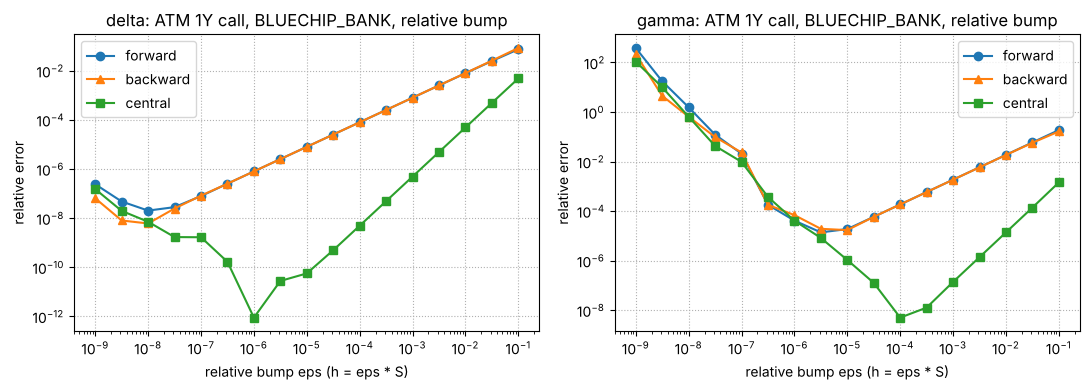

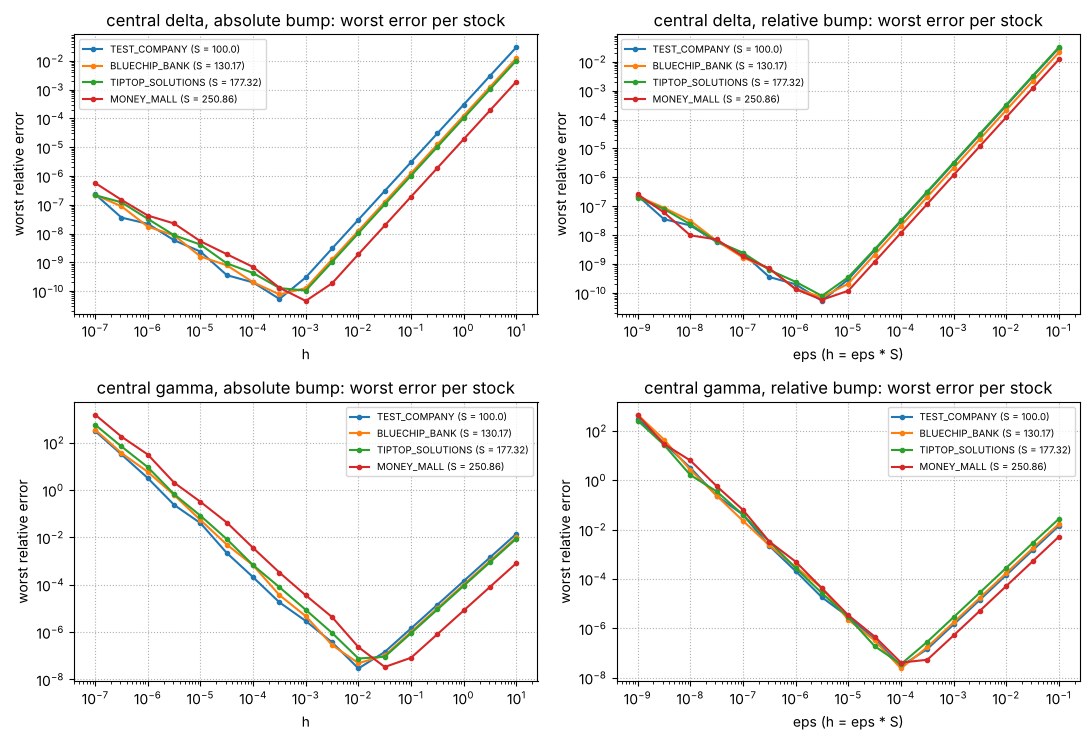

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

(here / 'figures').mkdir(exist_ok=True)
sizes = 10.0 ** -np.arange(1.0, 9.01, 0.5)                      # relative bumps eps = 1e-1, ..., 1e-9 (17 values)
abs_sizes = 10.0 ** -np.arange(-1.0, 7.01, 0.5)                 # absolute bumps h = 1e1, ..., 1e-7 (17 values)
greeks = ('delta', 'gamma')


def set_bump(fd_method: FDMethod, bump_type: BumpType, size: float) -> None:
    Pricer.fd_method, Pricer.bump_type = fd_method, bump_type   # class variables: used by every pricer
    if bump_type == BumpType.RELATIVE:
        Pricer.relative_bump_size = size
    else:
        Pricer.absolute_bump_size = size


def rel_error(pricer: Pricer, greek: str) -> float:
    exact = getattr(pricer, f'calc_{greek}')(GreekMethod.ANALYTIC)
    return abs(getattr(pricer, f'calc_{greek}')(GreekMethod.BUMP) - exact) / abs(exact)


# 1. ATM 1Y call on BLUECHIP_BANK (running example): relative error against eps, 3 methods
und = Stock.BLUECHIP_BANK
spot = MarketData.get_spot()[und]
atm = EuropeanAnalyticPricer(EuropeanContract(und, PutCallFwd.CALL, LongShort.LONG, spot, 1.0),
                             FlatVolModel(und), Params())
atm_err = {}
for fd_method in FDMethod:
    for greek in greeks:
        errs = []
        for eps in sizes:
            set_bump(fd_method, BumpType.RELATIVE, eps)
            errs.append(rel_error(atm, greek))
        atm_err[fd_method, greek] = np.array(errs)
print('1. ATM call, relative bump: relative error of delta | gamma')
print('eps     ' + ''.join(f'{m.value:>10s}' for m in FDMethod) + ' |' + ''.join(f'{m.value:>10s}' for m in FDMethod))
for i, eps in enumerate(sizes):
    print(f'{eps:7.0e} ' + ''.join(f'{atm_err[m, "delta"][i]:10.1e}' for m in FDMethod) + ' |'
          + ''.join(f'{atm_err[m, "gamma"][i]:10.1e}' for m in FDMethod))
for greek in greeks:                                            # slope of log(error) on eps in [1e-3, 1e-1]
    slopes = [np.polyfit(np.log10(sizes[:5]), np.log10(atm_err[m, greek][:5]), 1)[0] for m in FDMethod]
    print(f'slopes {greek}: ' + ', '.join(f'{m.value} {s:.2f}' for m, s in zip(FDMethod, slopes)))

# 2. the set of European options: 4 stocks x CALL, PUT x K/S = 0.9, 1, 1.1 x T = 0.5, 1, 2 (72 options)
book = [EuropeanAnalyticPricer(EuropeanContract(s, cp, LongShort.LONG, k * MarketData.get_spot()[s], t),
                               FlatVolModel(s), Params())
        for s in Stock for cp in (PutCallFwd.CALL, PutCallFwd.PUT) for k in (0.9, 1.0, 1.1) for t in (0.5, 1.0, 2.0)]
worst = {}                                                      # worst relative error over the options of a stock
for bump_type, grid in ((BumpType.RELATIVE, sizes), (BumpType.ABSOLUTE, abs_sizes)):
    for fd_method in FDMethod:
        for greek in greeks:
            table = np.zeros((len(Stock), len(grid)))
            for j, size in enumerate(grid):
                set_bump(fd_method, bump_type, size)
                for i, stock in enumerate(Stock):
                    table[i, j] = max(rel_error(p, greek) for p in book if p.contract.underlying == stock)
            worst[bump_type, fd_method, greek] = table
set_bump(FDMethod.CENTRAL, BumpType.RELATIVE, 0.01)             # back to the lecture's default
Pricer.absolute_bump_size = 1.0

# 3. suggested bump sizes: the grid value with the smallest worst error over all 72 options
print(f'\n2. {len(book)} options; suggested bumps (worst relative error over the set at that bump)')
print(f"{'greek':6s}{'method':9s}{'relative eps*':>14s}{'error':>9s}{'absolute h*':>13s}{'error':>9s}"
      + ''.join(f'{"h* " + s.value[:8]:>13s}' for s in Stock))
for greek in greeks:
    for fd_method in FDMethod:
        rel = worst[BumpType.RELATIVE, fd_method, greek].max(axis=0)
        ab = worst[BumpType.ABSOLUTE, fd_method, greek]
        per_stock = [abs_sizes[int(np.argmin(row))] for row in ab]
        print(f'{greek:6s}{fd_method.value:9s}{sizes[int(np.argmin(rel))]:14.0e}{rel.min():9.1e}'
              f'{abs_sizes[int(np.argmin(ab.max(axis=0)))]:13.0e}{ab.max(axis=0).min():9.1e}'
              + ''.join(f'{h:13.0e}' for h in per_stock))
print('spots: ' + ', '.join(f'{s.value} {MarketData.get_spot()[s]}' for s in Stock))
for greek in greeks:                                            # the relative eps* does not depend on the stock
    rows = worst[BumpType.RELATIVE, FDMethod.CENTRAL, greek]
    print(f'central {greek}, relative eps* per stock: ' + ', '.join(f'{sizes[int(np.argmin(r))]:.0e}' for r in rows))

# one relative bump for both greeks (the library has one relative_bump_size): central differences
both = np.maximum(worst[BumpType.RELATIVE, FDMethod.CENTRAL, 'delta'].max(axis=0),
                  worst[BumpType.RELATIVE, FDMethod.CENTRAL, 'gamma'].max(axis=0))
best = int(np.argmin(both))
lecture = int(np.argmin(abs(sizes - 0.01)))
print(f'central, one eps for delta and gamma: eps* = {sizes[best]:.0e}, worst error {both[best]:.1e}  '
      f'(lecture eps = 1e-02: {both[lecture]:.1e})')

# 4. data for the figures of the report (csv) and the figures (png)
np.savetxt(here / 'figures' / 'atm_errors.csv',
           np.column_stack([sizes] + [atm_err[m, g] for g in greeks for m in FDMethod]), delimiter=',',
           header='eps,' + ','.join(f'{g}_{m.value}' for g in greeks for m in FDMethod), comments='')
for bump_type, grid in ((BumpType.RELATIVE, sizes), (BumpType.ABSOLUTE, abs_sizes)):
    for greek in greeks:
        np.savetxt(here / 'figures' / f'worst_{greek}_{bump_type.value.lower()}_central.csv',
                   np.column_stack([grid, worst[bump_type, FDMethod.CENTRAL, greek].T]), delimiter=',',
                   header='size,' + ','.join(s.value for s in Stock), comments='')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, greek in zip(axes, greeks):
    for m, mark in zip(FDMethod, 'o^s'):
        ax.loglog(sizes, atm_err[m, greek], marker=mark, label=m.value.lower())
    ax.set_title(f'{greek}: ATM 1Y call, BLUECHIP_BANK, relative bump')
    ax.set_xlabel('relative bump eps (h = eps * S)')
    ax.set_ylabel('relative error')
    ax.grid(True, which='major', ls=':')
    ax.legend()
fig.tight_layout()
fig.savefig(here / 'figures' / 'q1_error_vs_bump.png', dpi=150)
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for row, greek in enumerate(greeks):
    for col, (bump_type, grid) in enumerate(((BumpType.ABSOLUTE, abs_sizes), (BumpType.RELATIVE, sizes))):
        ax = axes[row, col]
        for i, s in enumerate(Stock):
            ax.loglog(grid, worst[bump_type, FDMethod.CENTRAL, greek][i], marker='o', ms=3,
                      label=f'{s.value} (S = {MarketData.get_spot()[s]})')
        ax.set_title(f'central {greek}, {bump_type.value.lower()} bump: worst error per stock')
        ax.set_xlabel('h' if bump_type == BumpType.ABSOLUTE else 'eps (h = eps * S)')
        ax.set_ylabel('worst relative error')
        ax.grid(True, which='major', ls=':')
        ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(here / 'figures' / 'q1_absolute_vs_relative.png', dpi=150)
print('figures saved in figures/')
plt.show()